In [4]:
import pandas as pd
from pathlib import Path

# Upload your Excel file to Colab first
file_path = Path("C:/Users/waqar/OneDrive/Desktop/abihas mlp/Lumiere Research Data Analaysis.xlsx")

xls = pd.ExcelFile(file_path)

print(xls.sheet_names)

['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5', 'Sheet6', 'Sheet7', 'Sheet8']


In [6]:
import pandas as pd
import re

file_path = Path("Lumiere Research Data Analaysis.xlsx")

xls = pd.ExcelFile(file_path)

all_dfs = []

for sheet in xls.sheet_names:

    # Read first row to get material + energy
    title_df = pd.read_excel(
        file_path,
        sheet_name=sheet,
        header=None,
        nrows=1
    )

    title = str(title_df.iloc[0, 0])

    print(sheet, "->", title)

    # Extract energy
    energy = int(re.search(r"(\d+)\s*keV", title).group(1))

    # Identify material
    if "Sb" in title:
        material = "Cs3Sb2I9"
        b_element = "Sb"
    else:
        material = "CsPbI3"
        b_element = "Pb"

    # Read actual numeric data
    df = pd.read_excel(
        file_path,
        sheet_name=sheet,
        skiprows=4,
        header=None,
        usecols="A:D"
    )

    df.columns = [
        "depth_angstrom",
        "Cs_vacancies",
        "B_site_vacancies",
        "I_vacancies"
    ]

    # Remove empty/non-numeric rows
    df = df.dropna(subset=["depth_angstrom"])

    df["depth_angstrom"] = pd.to_numeric(
        df["depth_angstrom"],
        errors="coerce"
    )

    df = df.dropna(subset=["depth_angstrom"])

    # Add metadata
    df["energy_keV"] = energy
    df["material"] = material
    df["B_site_element"] = b_element
    df["source_sheet"] = sheet

    all_dfs.append(df)

Sheet1 -> CsPbI3 in 20 keV
Sheet2 -> CsPbI9 in 50 keV
Sheet3 -> CsPbI3 in 100 keV
Sheet4 -> CsPbI9 in 500 keV
Sheet5 -> Cs3Sb2I9 in 20 keV
Sheet6 -> Cs3Sb2I9 in 50 keV
Sheet7 -> Cs3Sb2I9 in 100 keV
Sheet8 -> Cs3Sb2I9 in 500 keV


In [9]:
data = pd.concat(all_dfs, ignore_index=True)

data.head()

,depth_angstrom,Cs_vacancies,B_site_vacancies,I_vacancies,energy_keV,material,B_site_element,source_sheet
0,100.01,0.000107,0.000105,0.000321,20,CsPbI3,Pb,Sheet1
1,200.01,0.000207,0.000212,0.000566,20,CsPbI3,Pb,Sheet1
2,300.01,0.000390,0.000356,0.000964,20,CsPbI3,Pb,Sheet1
3,400.01,0.000538,0.000529,0.001590,20,CsPbI3,Pb,Sheet1
4,500.01,0.000541,0.000541,0.001549,20,CsPbI3,Pb,Sheet1


In [10]:
data.groupby(["material", "energy_keV"]).size()

material  energy_keV
Cs3Sb2I9  20            100
          50            100
          100           100
          500           100
CsPbI3    20            100
          50            100
          100            96
          500           100
dtype: int64

In [11]:
data = pd.get_dummies(
    data,
    columns=["material"],
    dtype=int
)

In [12]:
mlp_df = data[
    [
        "energy_keV",
        "depth_angstrom",
        "material_CsPbI3",
        "material_Cs3Sb2I9",
        "Cs_vacancies",
        "B_site_vacancies",
        "I_vacancies"
    ]
]

In [13]:
mlp_df.head()

,energy_keV,depth_angstrom,material_CsPbI3,material_Cs3Sb2I9,Cs_vacancies,B_site_vacancies,I_vacancies
0,20,100.01,1,0,0.000107,0.000105,0.000321
1,20,200.01,1,0,0.000207,0.000212,0.000566
2,20,300.01,1,0,0.000390,0.000356,0.000964
3,20,400.01,1,0,0.000538,0.000529,0.001590
4,20,500.01,1,0,0.000541,0.000541,0.001549


In [14]:
# Inputs
features = [
    "energy_keV",
    "depth_angstrom",
    "material_CsPbI3",
    "material_Cs3Sb2I9"
]

# Targets
targets = [
    "Cs_vacancies",
    "B_site_vacancies",
    "I_vacancies"
]

X = mlp_df[features]
y = mlp_df[targets]

In [15]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Second split: temporary data into 15% validation + 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (557, 4) (557, 3)
Validation: (119, 4) (119, 3)
Test: (120, 4) (120, 3)


In [16]:
from sklearn.preprocessing import StandardScaler

x_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train)
X_val_scaled = x_scaler.transform(X_val)
X_test_scaled = x_scaler.transform(X_test)

In [17]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(y_train)
y_val_scaled = y_scaler.transform(y_val)
y_test_scaled = y_scaler.transform(y_test)

In [18]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

model = keras.Sequential([

    layers.Input(shape=(X_train_scaled.shape[1],)),

    layers.Dense(64, activation="relu"),

    layers.Dense(64, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(3)
])

In [19]:
X_train_scaled.shape[1]

4

In [20]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                320       
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 3)                 99        
                                                                 
Total params: 6,659
Trainable params: 6,659
Non-trainable params: 0
_________________________________________________________________


In [21]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

In [22]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

In [23]:
history = model.fit(
    X_train_scaled,
    y_train_scaled,

    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),

    epochs=500,
    batch_size=32,

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/500
18/18 [==============================] - 1s 8ms/step - loss: 0.9334 - mae: 0.6263 - val_loss: 0.4942 - val_mae: 0.4625
Epoch 2/500
18/18 [==============================] - 0s 2ms/step - loss: 0.8111 - mae: 0.5502 - val_loss: 0.4491 - val_mae: 0.4405
Epoch 3/500
18/18 [==============================] - 0s 2ms/step - loss: 0.7315 - mae: 0.5367 - val_loss: 0.4238 - val_mae: 0.4388
Epoch 4/500
18/18 [==============================] - 0s 2ms/step - loss: 0.6486 - mae: 0.5172 - val_loss: 0.4049 - val_mae: 0.4328
Epoch 5/500
18/18 [==============================] - 0s 2ms/step - loss: 0.5998 - mae: 0.5098 - val_loss: 0.4149 - val_mae: 0.4463
Epoch 6/500
18/18 [==============================] - 0s 2ms/step - loss: 0.5713 - mae: 0.4951 - val_loss: 0.3857 - val_mae: 0.4201
Epoch 7/500
18/18 [==============================] - 0s 2ms/step - loss: 0.5395 - mae: 0.4746 - val_loss: 0.3661 - val_mae: 0.4084
Epoch 8/500
18/18 [==============================] - 0s 2ms/step - loss: 0.5278 - m

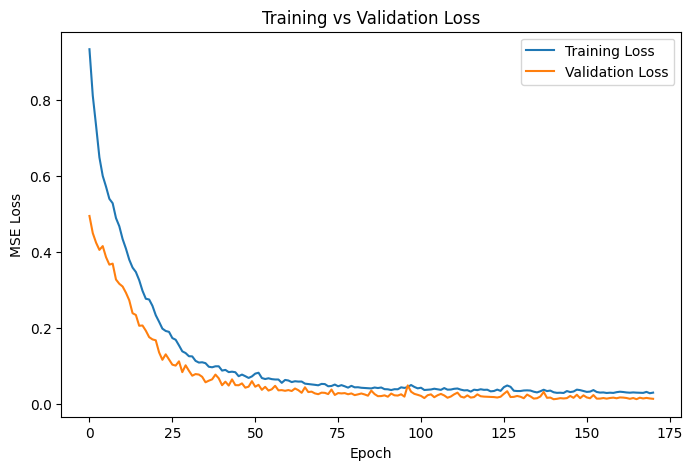

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

In [25]:
test_loss, test_mae = model.evaluate(
    X_test_scaled,
    y_test_scaled,
    verbose=0
)

print("Scaled Test MSE:", test_loss)
print("Scaled Test MAE:", test_mae)

Scaled Test MSE: 0.024146441370248795
Scaled Test MAE: 0.0930752381682396


In [26]:
y_pred_scaled = model.predict(X_test_scaled)

y_pred = y_scaler.inverse_transform(y_pred_scaled)

4/4 [==============================] - 0s 1ms/step


In [27]:
y_test_original = y_test.to_numpy()

In [28]:
print(y_pred[:5])

[[3.85326130e-04 2.55617371e-04 1.11586053e-03]
 [6.38082347e-05 6.28538182e-05 1.87244354e-04]
 [7.97456305e-05 5.09663332e-05 1.98883441e-04]
 [3.97631193e-05 2.39698056e-05 1.06925254e-04]
 [1.21536114e-05 3.65571736e-06 2.43449699e-06]]


In [29]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

target_names = [
    "Cs vacancies",
    "B-site vacancies",
    "I vacancies"
]

for i, name in enumerate(target_names):

    mae = mean_absolute_error(
        y_test_original[:, i],
        y_pred[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test_original[:, i],
            y_pred[:, i]
        )
    )

    r2 = r2_score(
        y_test_original[:, i],
        y_pred[:, i]
    )

    print(name)
    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R²  :", r2)
    print()

Cs vacancies
MAE : 2.0842064585059677e-05
RMSE: 3.246513645704703e-05
R²  : 0.985435957352299

B-site vacancies
MAE : 1.5542587633257454e-05
RMSE: 2.8402493238538625e-05
R²  : 0.9661759054030655

I vacancies
MAE : 4.1720166568190075e-05
RMSE: 6.31773200096881e-05
R²  : 0.9804490073686908



In [30]:
results = X_test.copy()

results["Cs_actual"] = y_test_original[:, 0]
results["Cs_predicted"] = y_pred[:, 0]

results["B_actual"] = y_test_original[:, 1]
results["B_predicted"] = y_pred[:, 1]

results["I_actual"] = y_test_original[:, 2]
results["I_predicted"] = y_pred[:, 2]

results.head(10)

,energy_keV,depth_angstrom,material_CsPbI3,material_Cs3Sb2I9,Cs_actual,Cs_predicted,B_actual,B_predicted,I_actual,I_predicted
636,100,4100.01,0,1,0.000380,0.000385,0.000237,0.000256,0.001150,0.001116
382,500,8700.01,1,0,0.000084,0.000064,0.000092,0.000063,0.000196,0.000187
783,500,8800.01,0,1,0.000076,0.000080,0.000037,0.000051,0.000214,0.000199
734,500,3900.01,0,1,0.000047,0.000040,0.000035,0.000024,0.000139,0.000107
76,20,7700.01,1,0,0.000000,0.000012,0.000000,0.000004,0.000000,0.000002
133,50,3400.01,1,0,0.000234,0.000261,0.000214,0.000196,0.000727,0.000644
275,100,7600.01,1,0,0.000001,0.000010,0.000001,0.000003,0.000000,0.000002
782,500,8700.01,0,1,0.000028,0.000078,0.000022,0.000050,0.000081,0.000196
625,100,3000.01,0,1,0.000266,0.000274,0.000163,0.000177,0.000758,0.000794
482,20,8700.01,0,1,0.000000,0.000009,0.000000,0.000004,0.000000,0.000013


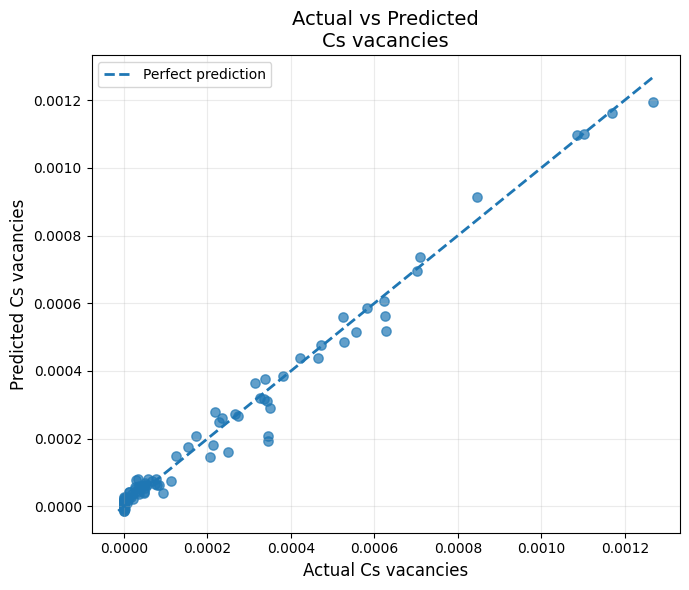

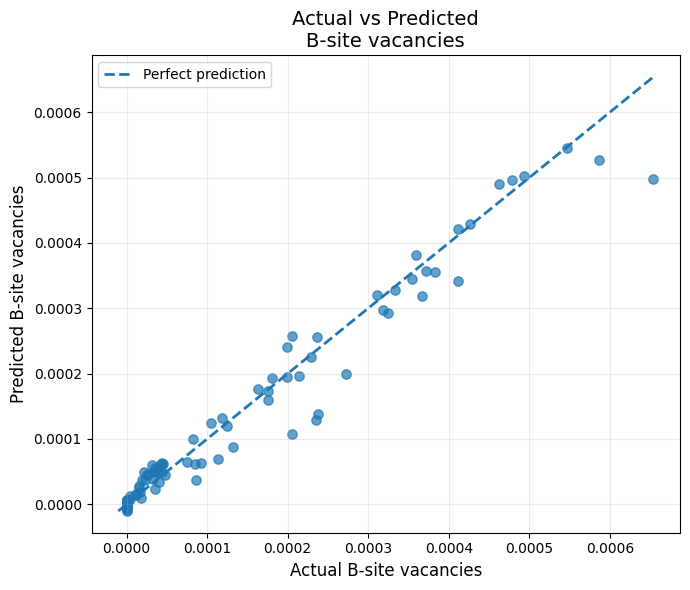

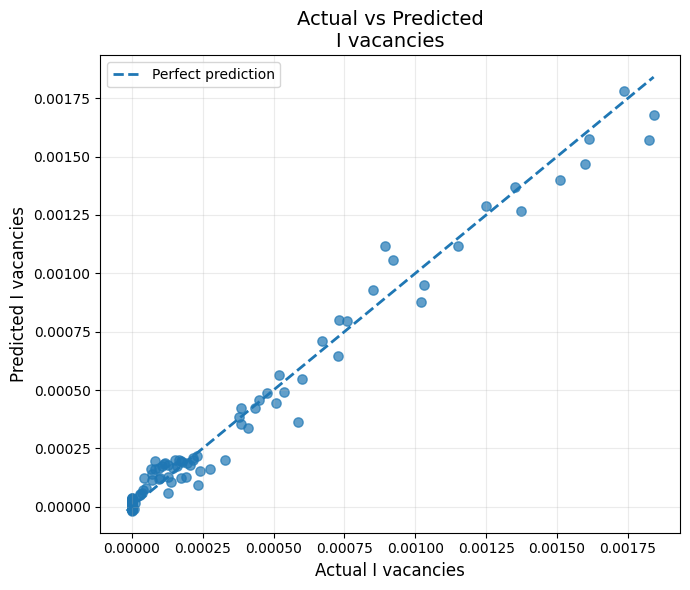

In [31]:
target_names = [
    "Cs vacancies",
    "B-site vacancies",
    "I vacancies"
]

for i, name in enumerate(target_names):

    actual = y_test_original[:, i]
    predicted = y_pred[:, i]

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    plt.figure(figsize=(7, 6))

    plt.scatter(
        actual,
        predicted,
        alpha=0.7,
        s=45
    )

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        linewidth=2,
        label="Perfect prediction"
    )

    plt.xlabel(f"Actual {name}", fontsize=12)
    plt.ylabel(f"Predicted {name}", fontsize=12)

    plt.title(
        f"Actual vs Predicted\n{name}",
        fontsize=14
    )

    plt.grid(alpha=0.25)
    plt.legend()

    plt.tight_layout()
    plt.show()

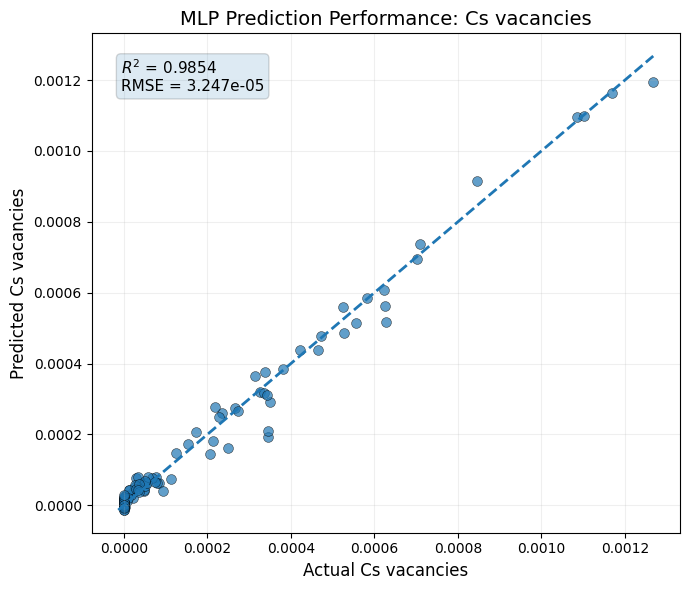

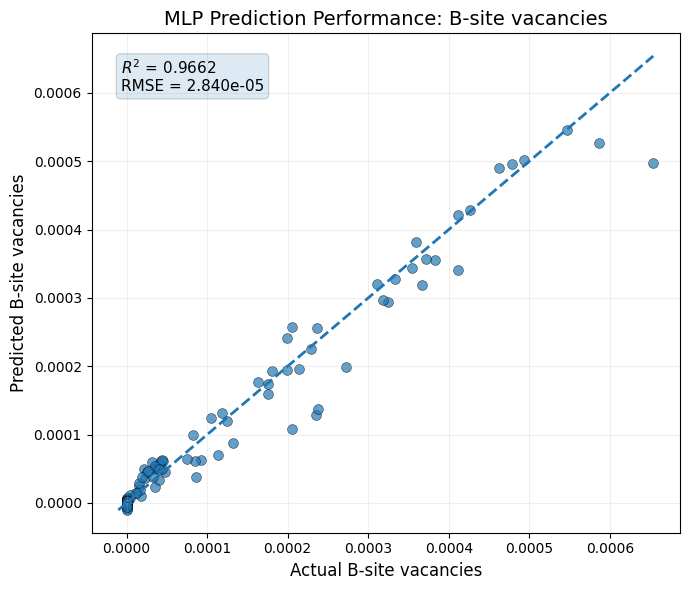

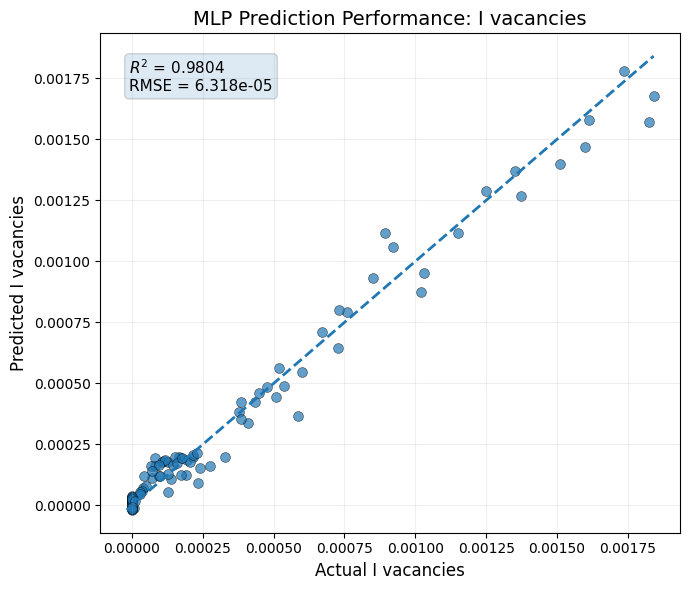

In [32]:
from sklearn.metrics import r2_score, mean_squared_error

target_names = [
    "Cs vacancies",
    "B-site vacancies",
    "I vacancies"
]

for i, name in enumerate(target_names):

    actual = y_test_original[:, i]
    predicted = y_pred[:, i]

    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    plt.figure(figsize=(7, 6))

    plt.scatter(
        actual,
        predicted,
        s=50,
        alpha=0.7,
        edgecolors="black",
        linewidth=0.4
    )

    plt.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        linewidth=2
    )

    plt.text(
        0.05,
        0.95,
        f"$R^2$ = {r2:.4f}\nRMSE = {rmse:.3e}",
        transform=plt.gca().transAxes,
        fontsize=11,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round",
            alpha=0.15
        )
    )

    plt.xlabel(f"Actual {name}", fontsize=12)
    plt.ylabel(f"Predicted {name}", fontsize=12)

    plt.title(
        f"MLP Prediction Performance: {name}",
        fontsize=14
    )

    plt.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

In [33]:
plot_df = results[
    (results["energy_keV"] == 100) &
    (results["material_CsPbI3"] == 1)
].copy()

plot_df = plot_df.sort_values("depth_angstrom")